# Statistical background: what `det_stat` computes

This part collects the mathematics behind `emrisearch.jax_utils.det_stat` (and `cpu_det_stat`) so that the numbers printed further down can be interpreted. It refers only to the `emrisearch` code path used in this notebook.

## 1. Conventions

| symbol | meaning | code |
|---|---|---|
| $T$, $\Delta f=1/T$ | SFT duration and frequency resolution | `T_sft`, `deltaf` |
| $f_k=k\,\Delta f$ | frequency of SFT bin $k$ | `k_min_max * deltaf` |
| $\alpha$ | SFT segment index; $t_\alpha$ is its start time | `t_alpha` |
| $w(\tau)$ | Tukey window applied when the SFTs are built (taper fraction $\alpha_w=0.1$) | `injection_dict['wind']` |
| $\tilde d_\alpha(f_k)$ | SFT of the data, $\Delta t\sum_j w_j\,d(t_{\alpha,j})\,e^{-2\pi i f_k t_{\alpha,j}}$ | `data_sfts` |
| $S_n(f)$ | one-sided noise PSD | `psd` |
| $f_\alpha,\ \dot f_\alpha$ | track frequency and its derivative at segment $\alpha$ | `f_alpha`, `fdot_alpha` |
| $P$ | half-width (in bins) of the frequency window around the track | `P` (default 100) |
| $f_w$ | $\frac1T\int_0^T w^2\,d\tau$ (for Tukey, $1-\tfrac58\alpha_w=0.9375$) | `window_factor` |
| $N_{\rm active}$ | number of segments that pass the mask inside `det_stat` (below) | |

**Noise model.** One-sided PSD, bins treated as independent:
$$E\!\left[\tilde n^*_\alpha(f_k)\,\tilde n_\alpha(f_j)\right]=\frac{S_n(f_k)}{2\,\Delta f}\,\delta_{kj}.$$
Under this model, for a fixed template $q$, $\langle q|n\rangle\sim\mathcal N(0,\langle q|q\rangle)$ with $\langle a|b\rangle=4\,\Re\sum_k\tilde a^*\tilde b\,\Delta f/S_n$. The noise-only check below confirms this normalisation for `generate_noise` with the TDI `psd`.

## 2. The statistic

**Kernel.** For a linear chirp the SFT of a unit-amplitude signal is proportional to
$$K(f_0,f_1,T)=\int_0^T e^{2\pi i\,(f_0\tau+\frac12 f_1\tau^2)}\,d\tau,$$
implemented by `robust_kernel` (Fresnel integrals, Dirichlet kernel when $f_1=0$). **This kernel is rectangular: it has no taper**, while the data SFTs are Tukey-windowed (see §4).

**Matched filter per segment** (`c_alpha` in the code):
$$c_\alpha=\sum_{k=k_\alpha-P}^{k_\alpha+P}\tilde d^{\,*}_\alpha(f_k)\,K(f_\alpha-f_k,\dot f_\alpha,T)\,\frac{\Delta f}{S_n(f_k)},\qquad k_\alpha=\lfloor f_\alpha T\rfloor ,$$
with out-of-range bins masked. The code conjugates the data, so $c_\alpha$ is the complex conjugate of the "natural" filter; $|c_\alpha|$ is unaffected.

**Template norm** (`hh_term`, with unit amplitude): $\rho_\alpha\simeq T/S_n(f_\alpha)$.

**Statistic.** With the active-segment mask
$$\text{active}_\alpha:\quad f_\alpha>10^{-3.5}\ \text{Hz}\ \ \text{and}\ \ \Delta\phi_\alpha=\left|\ddot f_\alpha T^3/6\right|<1,\qquad \ddot f=\texttt{gradient}(\dot f,T),$$
`det_stat` returns (and `0` if no segment is active)
$$\boxed{\ \mathcal D=\sum_{\alpha\in\text{active}}\frac12\,\frac{(2|c_\alpha|)^2}{\rho_\alpha}=\sum_{\alpha\in\text{active}}\frac{2\,|c_\alpha|^2}{\rho_\alpha}\ }$$
(`cpu_det_stat` is the same expression written with an explicit amplitude $A_\alpha$, which cancels).

## 3. Why $2|c|^2/\rho$: from the Gaussian likelihood, and where "$N/2$" goes

For whitened data the Gaussian log-likelihood of a model $h$ is
$$\ln\mathcal L(h)=-\tfrac12\langle d-h|d-h\rangle=-\tfrac12\langle d|d\rangle+\Lambda(h),\qquad \Lambda(h)=\langle h|d\rangle-\tfrac12\langle h|h\rangle .$$
Under noise $\langle d|d\rangle\sim\chi^2_N$ ($N$ = number of real data points), so the first term averages $-N/2$. That is the "$N/2$" of the standard likelihood. It does not depend on the template, so it is dropped and one works with the log-likelihood ratio $\Lambda$.

A segment signal is linear in two real amplitudes, $h_\alpha=a\,q_c+b\,q_s$ with $a=A\cos\phi$, $b=A\sin\phi$, where $q_s$ is the quadrature partner of $q_c$, the two being orthogonal with $\langle q_c|q_c\rangle=\langle q_s|q_s\rangle=\rho_\alpha$. The projections of the data are $x_c=\langle q_c|d\rangle=2\Re c_\alpha$ and $x_s=\langle q_s|d\rangle=\pm2\Im c_\alpha$. Maximising $\Lambda=a\,x_c+b\,x_s-\tfrac12\rho_\alpha(a^2+b^2)$:
$$\hat a=x_c/\rho_\alpha,\quad \hat b=x_s/\rho_\alpha,\qquad \Lambda_{\max}=\frac{x_c^2+x_s^2}{2\rho_\alpha}=\frac{2|c_\alpha|^2}{\rho_\alpha}\equiv\mathcal F_\alpha .$$

**General rule.** Maximising $\Lambda$ over $k$ linear parameters splits $\langle d|d\rangle=\langle r|r\rangle+2\Lambda_{\max}$ (residual plus fitted part). Under noise, by Cochran's theorem, $2\Lambda_{\max}\sim\chi^2_k$ and $E[\Lambda_{\max}]=k/2$. Here $k=2$ per segment (amplitude *and* phase are profiled), so $E[\mathcal F_\alpha]=1$ and $\mathcal F_\alpha\sim\tfrac12\chi^2_2=\mathrm{Exp}(1)$. A statistic with the phase held fixed ($k=1$) would average $\tfrac12$ per segment, which is where an "$N/2$" would reappear.

## 4. Expected values of `det_stat` with this implementation

If the template were exactly matched to the data (same window, exact $\rho_\alpha$) the results would be the standard ones: noise gives $E[\mathcal D]=N_{\rm active}$, signal gives $E[\mathcal D]=N_{\rm active}+\tfrac12\sum_\alpha\mathrm{SNR}_\alpha^2$. In `emrisearch` the data are Tukey-windowed but the kernel is rectangular and $\rho_\alpha\simeq T/S_n(f_\alpha)$, which changes the scale.

**Noise only.** Assume $S_n$ is flat over the kernel. By Parseval $c_\alpha\simeq\frac1{S_n}\int q(t)\,w(t)\,n(t)\,dt$ with $|q|=1$ and $E[n(t)n(t')]=\tfrac{S_n}2\delta(t-t')$, so
$$E|c_\alpha|^2=\frac{1}{2S_n}\int_0^T w^2\,dt=\frac{T f_w}{2S_n}\quad\Rightarrow\quad E[\mathcal F_\alpha]=\frac{2\cdot Tf_w/(2S_n)}{T/S_n}=f_w .$$

| | mean | variance |
|---|---|---|
| per active segment, noise | $f_w$ | $f_w^2$ ($\mathcal F_\alpha\simeq f_w\cdot\mathrm{Exp}(1)$) |
| `det_stat`, noise | $\boxed{N_{\rm active}\,f_w}$ | $N_{\rm active}\,f_w^2$ |

The correct comparison in the notebook is therefore $\mathcal D$ against $N_{\rm active}f_w$, with a standard deviation of $f_w\sqrt{N_{\rm active}}$ (about 11–12 for roughly 150 active segments).

**Signal present.** The signal part of $c_\alpha$ is $\frac{A_\alpha}{2S_n}\int w\,dt$, so the signal adds
$$\tfrac12\,\frac{A^2T}{S_n}\left(\frac{\int w\,dt}{T}\right)^2=\tfrac12\,\mathrm{SNR}^2_{\rm rect}\,(1-\tfrac{\alpha_w}{2})^2\quad\text{per segment},$$
with $\mathrm{SNR}^2_{\rm rect}=A^2T/S_n$. At $\alpha_w=0.1$ a rectangular template on windowed data keeps $0.95^2\approx90\%$ of the signal term, and the noise term is scaled by $f_w\approx94\%$. In total
$$E[\mathcal D]\simeq N_{\rm active}f_w+\tfrac12\sum_{\alpha}\mathrm{SNR}^2_{{\rm rect},\alpha}\,(1-\tfrac{\alpha_w}2)^2 .$$
Also, $\mathcal D(d)\neq\mathcal D(h)+\mathcal D(n)$ for data $d=h+n$: $|c_h+c_n|^2=|c_h|^2+|c_n|^2+2\Re(c_h^*c_n)$, and the cross term has zero mean but non-zero scatter.

**Caveats.** (i) The window correlates neighbouring SFT bins, so the diagonal noise model is only approximate (the exact scaling is within the same few-percent range). (ii) $\rho_\alpha=T/S_n(f_\alpha)$ is exact only if $S_n$ is flat across the kernel and the $\pm P$ window captures all its power; the per-bin value is $\rho_\alpha=\sum_k|K|^2\Delta f/S_n(f_k)$. At low frequency, where $S_n$ varies strongly from bin to bin, the two differ.

## 5. Using $\mathcal D$ for optimisation and sampling

* **Scale.** $\mathcal D=\sum_\alpha\mathcal F_\alpha$ is on the **log-likelihood** scale (profiled over each segment's amplitude and phase). The $\chi^2$ scale is $2\mathcal D$. For an MCMC or nested-sampling run use $\ln\mathcal L=\mathcal D$ without extra factors. Using $2\mathcal D$ raises the likelihood to the power 2, which narrows posteriors by $\sqrt2$ and distorts evidences. Differential evolution and Adam are unaffected by the factor, but thresholds and $p$-values are. Check the calibration with an injection–recovery test: the true parameters should fall inside the 68% and 95% credible intervals the right fraction of the time.
* **Baseline.** Under noise $\mathcal D\approx N_{\rm active}f_w$ and $N_{\rm active}$ depends on the track (the mask in §2). Raw values at different tracks are therefore not directly comparable. Use $\mathcal D-N_{\rm active}f_w$, or $(\mathcal D-N_{\rm active}f_w)/(f_w\sqrt{N_{\rm active}})$.
* **Profiled versus marginalised.** $\mathcal D$ maximises over $2N_{\rm active}$ nuisance amplitudes and phases. Marginalising them with a flat prior in $(A\cos\phi,A\sin\phi)$ per segment gives $\sum_\alpha(\mathcal F_\alpha-\ln\rho_\alpha)$. With $\rho_\alpha=T/S_n(f_\alpha)$ the extra term is $+\sum_\alpha\ln S_n(f_\alpha)$, which depends on the track and can shift $\ln\mathcal L$ by tens of units across 150 segments. Which form is appropriate depends on the prior; if the amplitudes are fixed by the physical parameters, a coherent likelihood with $A_\alpha(\theta)$ is more informative than either.
* **Semicoherent likelihood.** Summing independent per-segment fits discards the amplitude and phase relationships between segments, so posteriors from $\mathcal D$ are wider than from a fully coherent model.

## 6. Implementation points to be aware of (`emrisearch`)

1. **Rectangular kernel, windowed data, $\rho\approx T/S_n(f_\alpha)$**: scales the statistic by $f_w$ in noise and by about $0.9$ for the signal term (§4).
2. **No phase factor $e^{-2\pi i f_kt_\alpha}$** in `det_stat` / `cpu_det_stat`. A time-shift-consistent filter includes it. The two agree only if $f_kt_\alpha$ is an integer for every bin (e.g. $t_\alpha$ a multiple of $T$ with a convention in which the SFT already refers to absolute time). Which one is right depends on the phase convention of `compute_sfts`.
3. **Different masks.** `cpu_det_stat` uses `k < shape[0]//2` and (in the `__main__` example) cuts on $f$ and $\dot f$. `det_stat` uses `k < shape[0]` and cuts on $f$ and $\Delta\phi$. $\Delta\phi=|\ddot fT^3/6|$ is in cycles, so the threshold 1.0 is $2\pi$ looser than "1 radian". `jnp.gradient(fdot, T_sft)` also assumes consecutive segments spaced exactly $T$ apart.
4. **`psd`.** Below $10^{-4}$ Hz it returns `cs(1e-4)` (the LPA-based curve) even when `tdi_flag=True`; `np.clip(Sn_tdi, Sn_tdi[0], None)` sets a floor (not a cap) at the first value; the spline is linear-in-$f$, linear-in-$S$ across decades, which can ring or go negative between points. A single PSD is used for all channels.
5. **Precision at small $\dot f$.** For tiny non-zero $f_1$, the Fresnel argument $f_0/f_1$ becomes large and accuracy degrades.
6. **Hidden NaNs.** `nan_to_num` in `cpu_det_stat` hides $0/0$ from inactive segments and gives NaN gradients there; `det_stat` returns exactly `0.0` when no segment is active, which is not on the same scale as other tracks.

Cells below are the original ones. Short notes are added before the cells they relate to.

In [1]:
import os
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import optax
import matplotlib.pyplot as plt
import numpy as np
from few.utils.constants import YRSID_SI
from emrisearch.jax_utils import psd, det_stat, cpu_det_stat
from emrisearch.search_utils import generate_emri_signal_and_sfts
from emrisearch.emri_utils import get_f_fdot_fddot_back
from tqdm import trange
from emrisearch.search_utils import det_stat as det_stat_evolution

def f_fdot_fddot(params, t_alpha):
    params_in = np.append(params, 1.0)
    _, f, dotf, dotdotf = get_f_fdot_fddot_back(params_in, t_alpha)
    return f, dotf, dotdotf

def get_loglike(params, t_alpha, data_sfts_in, m_phi=2, n_r=0):
    f_, fdot_, _ = f_fdot_fddot(params, t_alpha)
    f_a = jnp.abs(jnp.asarray(m_phi*f_[0] + n_r*f_[1], dtype=jnp.float64))
    fdot_a = jnp.abs(jnp.asarray(m_phi*fdot_[0] + n_r*fdot_[1], dtype=jnp.float64))
    ll_d = det_stat(data_sfts_in, f_a, fdot_a, T_sft=T_sft)
    return ll_d


/opt/miniconda3/envs/emri/lib/python3.12/site-packages/lisaconstants/compat/astropy.py:252: UserWarning: The following constants differ between lisaconstants and the version of astropy you have installed: VACUUM_PERMEABILITY. The recommended version of astropy is 7.2.0. Use a different one at your own risks. 
You may also open an issue at https://gitlab.esa.int/lisa-sgs/commons/lisa-constants to warn that lisaconstants is not compatible with astropy v8.0.1
  warnings.warn(


Using TDI PSD
Using TDI PSD


## Step 1: Set Parameters

Define the EMRI parameters and search settings. To reduce computational cost, we search for a single plunge time (`Tpl`) and use a smaller batch size.

In [2]:
# EMRI and search parameters
m1 = 4e6  # Primary mass (solar masses)
m2 = 10.  # Secondary mass (solar masses)
a = 0.0 # Spin parameter
Tpl = 0.9  # Plunge time (years)
ef = 0.0  # Final eccentricity initial 0.015
T_sft = 2 * 86400.  # SFT duration (seconds)
T_data = 1.0  # Total data duration (years)
deltaT = 5.0  # Time step (seconds)
snr_ref = 50.0  # Reference SNR
T_snr = 1.0  # SNR duration (years)
output_dir = './test/'  # Output directory
os.makedirs(output_dir, exist_ok=True)
np.random.seed(2601)

## Step 2: Generate EMRI Signal and SFTs

Generate the simulated EMRI signal and Short Fourier Transforms (SFTs) using the provided utility function.

In [3]:
true_values = np.array([m1, m2, a, Tpl, ef, 1.0])

injection_dict = generate_emri_signal_and_sfts(true_values, T_data, T_sft, deltaT, snr_ref, T_snr)
t_alpha = injection_dict['t_alpha']
phi, f_phi_r, dotf, dotdotf = injection_dict['true_phi_f_fdot_fddot']
samples_per_sft = injection_dict['samples_per_sft']
data_sfts = jnp.asarray(injection_dict['data_sfts'], dtype=jnp.complex128)
noise_sfts = jnp.asarray(injection_dict['noise_sfts'], dtype=jnp.complex128)
signal_sfts = jnp.asarray(injection_dict['signal_sfts'], dtype=jnp.complex128)

Using response generator
Waveform generated on CPU
Final SNR: 49.99999999999999


In [4]:
f_test, _, _ = f_fdot_fddot(true_values[:-1], t_alpha)
(f_test == f_phi_r).all()

np.True_

## Step 3: Plot True Frequency Track

Visualize the true frequency track in the SFT data for the harmonic (m=2, n=0).

Log-likelihood ratio (m,n)=(2,0): 644.1531499464609 = 485.1134218438534 + 154.10789893935151
Log-likelihood ratio (m,n)=(3,0): 449.25613689022265 = 324.44838734688454 + 154.5016444954937
Log-likelihood ratio (m,n)=(4,0): 295.5241753507178 = 137.00404170248393 + 143.95813652495173
Log-likelihood ratio (m,n)=(5,0): 180.77232967334095 = 40.480626193812284 + 141.83746079255172


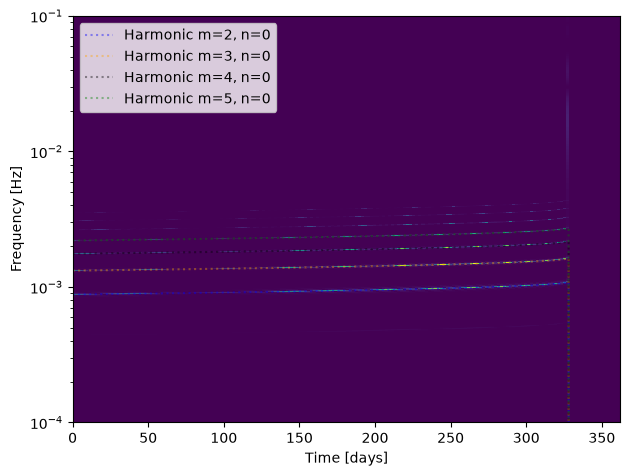

In [5]:
frequencies = np.fft.rfftfreq(samples_per_sft, deltaT)
plt.figure()
plt.imshow(np.abs(injection_dict['signal_sfts']),aspect='auto',origin='lower',extent=[0, t_alpha[-1]/86400, frequencies[0], frequencies[-1]],cmap='viridis')
plt.ylim(1e-4, 0.015)
for m,n,col in [(2,0,"blue"), (3,0,"orange"), (4,0,"black"), (5,0,"green")]:
    f_alpha = jnp.abs(jnp.asarray(m*f_phi_r[0] + n*f_phi_r[1], dtype=jnp.float64))
    fdot_alpha = jnp.abs(jnp.asarray(m*dotf[0] + n*dotf[1], dtype=jnp.float64))
    ll_d = det_stat(injection_dict['data_sfts'], f_alpha, fdot_alpha, T_sft=T_sft)
    ll_h = det_stat(injection_dict['signal_sfts'], f_alpha, fdot_alpha, T_sft=T_sft)
    ll_n = det_stat(injection_dict['noise_sfts'], f_alpha, fdot_alpha, T_sft=T_sft)
    print(f"Log-likelihood ratio (m,n)=({m},{n}): {ll_d} = {ll_h} + {ll_n}")
    plt.plot(t_alpha/86400, f_alpha, ':', label=f'Harmonic m={m}, n={n}', alpha=0.4, color=col)

plt.semilogy()
plt.legend(loc='upper left')
plt.xlabel('Time [days]')
plt.ylabel('Frequency [Hz]')
plt.tight_layout()
plt.ylim(1e-4, 0.1)
plt.savefig(output_dir + '/true_frequency_track.png', dpi=300)

### Check 1: noise-only expectation

`det_stat` on pure noise should average $N_{\rm active}f_w$ with standard deviation $f_w\sqrt{N_{\rm active}}$ (§4). The next cell evaluates it for (i) one noise realisation against 100 scaled tracks (`factor * f_alpha`), and (ii) 100 independent noise realisations against the single track left over in `f_alpha` from the plotting loop (the $m=5$ harmonic). Ensemble (ii) is the clean test. In (i) $N_{\rm active}$ changes with the scale factor, so the pooled values mix different expectations.

In [6]:
from emrisearch.da_utils import generate_noise, compute_sfts

window_factor = (injection_dict['wind']**2).sum()/len(injection_dict['wind'])
list_loglike_nn = np.asarray([det_stat(injection_dict['noise_sfts'], factor*f_alpha, factor*fdot_alpha, T_sft=T_sft) 
                    for factor in np.linspace(0.5, 10, 100)])
list_alt = []
for real_i in range(100):
    print(f"Realization {real_i+1}/100")
    noise = generate_noise(int(YRSID_SI*T_data/deltaT), deltaT, psd)
    noise_ = compute_sfts(noise, deltaT, injection_dict['wind'], samples_per_sft)
    list_alt.append(det_stat(noise_, f_alpha, fdot_alpha, T_sft=T_sft))

list_alt = np.asarray(list_alt)


Realization 1/100
Realization 2/100
Realization 3/100
Realization 4/100
Realization 5/100
Realization 6/100
Realization 7/100
Realization 8/100
Realization 9/100
Realization 10/100
Realization 11/100
Realization 12/100
Realization 13/100
Realization 14/100
Realization 15/100
Realization 16/100
Realization 17/100
Realization 18/100
Realization 19/100
Realization 20/100
Realization 21/100
Realization 22/100
Realization 23/100
Realization 24/100
Realization 25/100
Realization 26/100
Realization 27/100
Realization 28/100
Realization 29/100
Realization 30/100
Realization 31/100
Realization 32/100
Realization 33/100
Realization 34/100
Realization 35/100
Realization 36/100
Realization 37/100
Realization 38/100
Realization 39/100
Realization 40/100
Realization 41/100
Realization 42/100
Realization 43/100
Realization 44/100
Realization 45/100
Realization 46/100
Realization 47/100
Realization 48/100
Realization 49/100
Realization 50/100
Realization 51/100
Realization 52/100
Realization 53/100
Re

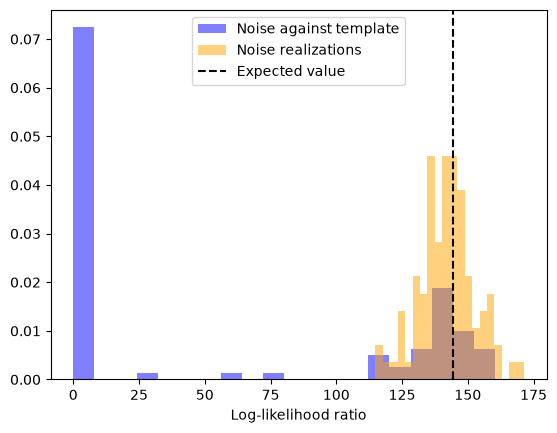

In [7]:
plt.figure()
plt.hist(list_loglike_nn, color='blue', alpha=0.5, density=True, bins=20, label='Noise against template')
plt.hist(list_alt.flatten(), color='orange', alpha=0.5, density=True, bins=20, label='Noise realizations')
plt.axvline(window_factor * (f_alpha != 0.0).sum(), label='Expected value', color='k', linestyle='--')
plt.legend()
plt.xlabel('Log-likelihood ratio')
plt.show()

**Reading the histogram.** The dashed line above is `window_factor * (f_alpha != 0).sum()`, which counts all segments with non-zero frequency, not the segments that pass the mask inside `det_stat`. The exact expectation uses $N_{\rm active}$. The cell below computes it with a helper that mirrors the mask used in `jax_utils.det_stat` (if that mask changes, update the helper) and reports a z-score for the 100 independent realisations. Expected: mean z-score $0\pm0.1$ and standard deviation $1\pm0.07$.

In [8]:
def n_active(f_a, fdot_a, T=T_sft):
    """Number of segments that jax_utils.det_stat sums over (mirrors its mask:
    f > 10^-3.5 Hz and |fddot * T^3 / 6| < 1, with fddot = gradient(fdot, T))."""
    fddot_a = jnp.gradient(fdot_a, T)
    return int(((f_a > 10**(-3.5)) & (jnp.abs(fddot_a * T**3 / 6) < 1.0)).sum())

n_act = n_active(f_alpha, fdot_alpha)
mu, sigma = n_act * window_factor, np.sqrt(n_act) * window_factor
vals = np.asarray(list_alt).ravel()
z = (vals - mu) / sigma
print(f"N_active = {n_act}: expected mean = {mu:.2f}, expected std = {sigma:.2f}")
print(f"observed mean = {vals.mean():.2f}, observed std = {vals.std(ddof=1):.2f}")
print(f"z-score mean = {z.mean():.2f} (expect 0 +/- {1/np.sqrt(len(z)):.2f}), "
      f"z-score std = {z.std(ddof=1):.2f} (expect 1 +/- {1/np.sqrt(2*(len(z)-1)):.2f})")

N_active = 165: expected mean = 144.37, expected std = 11.24
observed mean = 141.98, observed std = 10.57
z-score mean = -0.21 (expect 0 +/- 0.10), z-score std = 0.94 (expect 1 +/- 0.07)


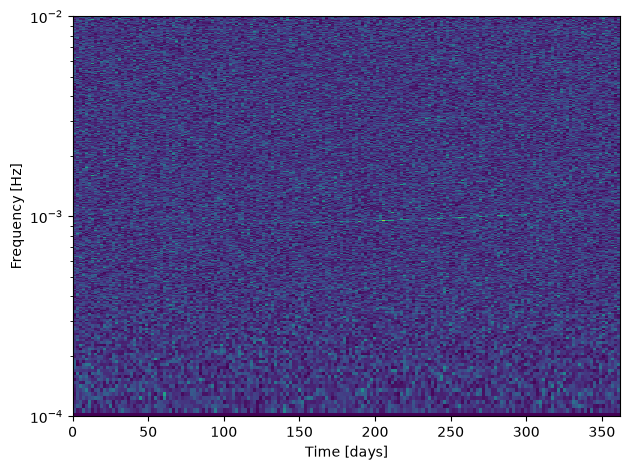

In [9]:
toplot = np.array(data_sfts) / np.array(psd(frequencies))[:,None]**0.5

plt.figure()
plt.imshow(np.abs(toplot), aspect='auto', origin='lower',
           extent=[0, t_alpha[-1]/86400, frequencies[0], frequencies[-1]], cmap='viridis')
plt.ylim(1e-4, 0.01)
plt.semilogy()
plt.xlabel('Time [days]')
plt.ylabel('Frequency [Hz]')
plt.tight_layout()
plt.savefig(output_dir + '/injected_data_sft.png', dpi=300)
plt.show()

### Check 2: per-segment statistic evolution (`det_stat_evolution`)

Here `S = |dh|**2 / hh`, i.e. $S_\alpha=4|c_\alpha|^2/\rho_\alpha=2\mathcal F_\alpha$. The detection statistic is therefore $\tfrac12\sum_\alpha S_\alpha$ (the first printed number, "Noise sum"), and $E[\sum_\alpha S_\alpha]=2N_{\rm active}f_w$ under noise. **The second printed number is $2N_{\rm active}f_w=E[\sum S]$, so it should be compared with $\sum S$, or half of it with the first number.** The stored output has $154.1,\ 154.5,\ 144.0,\ 142.9$ against $285.24/2=142.62$: all within about $1\sigma$ ($\sigma\approx f_w\sqrt{N_{\rm active}}$), so the noise normalisation and the factor $f_w$ are consistent and there is no stray factor 2.

Two things to be aware of in this cell:

* `A_alpha` is built once, before the loop, from the `f_alpha`/`fdot_alpha` left over from the plotting loop (the $m=5$ track), and then reused for $m=2,\dots,5$. That is why the printed expected value is identical (285.24) for all four harmonics, and the mask differs from the harmonic-specific mask applied inside `jax_utils.det_stat`.
* The two values compared at the end of each iteration ("Log-likelihood ratio" from the evolution function versus "Test log-likelihood" from `jax_utils.det_stat`) agree to about 0.4–1.4% in the stored output, which is the size one expects from the different masks and cuts, but this was not checked in detail.

In [10]:
fdot_alpha = np.gradient(f_alpha, t_alpha)
fddot_alpha = np.gradient(fdot_alpha, t_alpha)
delta_phi_approx = np.abs(fddot_alpha * T_sft**3 / 6)
A_alpha = np.where((f_alpha > 10**(-3.5)) & (fdot_alpha > 1e-13) & (delta_phi_approx < 1.0), 1.0, 0.0)
phi_alpha = np.ones_like(f_alpha)

mfilter_hh = injection_dict['m_hh']
mfilter_dh = np.abs(injection_dict['m_hd'])**2/(mfilter_hh)

S_sig_dict = {}
S_data_dict = {}
S_noise_dict = {}
for m,n,col in [(2,0,"blue"), (3,0,"orange"), (4,0,"black"), (5,0,"green")]:#, (6,0,"red"), (7,0, "purple"), (8,0, "brown"), (9,0, "pink"), (10,0, "gray")]:
    phi_alpha = jnp.asarray(m*phi[0] + n*phi[1], dtype=jnp.float64)
    f_alpha = jnp.abs(jnp.asarray(m*f_phi_r[0] + n*f_phi_r[1], dtype=jnp.float64))
    fdot_alpha = jnp.abs(jnp.asarray(m*dotf[0] + n*dotf[1], dtype=jnp.float64))
    dh, hh = det_stat_evolution(np.asarray(data_sfts), A_alpha, phi_alpha, f_alpha, fdot_alpha, T_sft=T_sft)
    tan_phi_data = np.imag(dh) / np.abs(dh)
    S_data = np.abs(dh)**2 / hh
    S_data_dict[(m,n)] = S_data
    
    dh, hh = det_stat_evolution(np.asarray(signal_sfts), A_alpha, phi_alpha, f_alpha, fdot_alpha, T_sft=T_sft)
    S_signal = np.abs(dh)**2 / hh
    S_sig_dict[(m,n)] = S_signal

    dh, hh = det_stat_evolution(np.asarray(noise_sfts), A_alpha, phi_alpha, f_alpha, fdot_alpha, T_sft=T_sft)
    S_noise = np.abs(dh)**2 / hh
    S_noise_dict[(m,n)] = S_noise

    print(f"Noise sum", np.nan_to_num(S_noise).sum() * 0.5, 2 * (np.nan_to_num(S_noise) != 0).sum() * window_factor)

    print(f"Log-likelihood ratio (m,n)=({m},{n}): {np.nan_to_num(S_data).sum()/2.}, {np.nan_to_num(S_signal).sum()/2.}")
    test_ll = get_loglike(true_values[:-1], t_alpha, data_sfts, m_phi=m, n_r=n)
    print(f"Test log-likelihood (m,n)=({m},{n}): {test_ll}")

/var/folders/78/stbtx34d7vj939lq8bmh39wrx379gb/T/ipykernel_54714/1241379015.py:8: RuntimeWarning: invalid value encountered in divide
  mfilter_dh = np.abs(injection_dict['m_hd'])**2/(mfilter_hh)
/var/folders/78/stbtx34d7vj939lq8bmh39wrx379gb/T/ipykernel_54714/1241379015.py:19: RuntimeWarning: invalid value encountered in divide
  S_data = np.abs(dh)**2 / hh
/var/folders/78/stbtx34d7vj939lq8bmh39wrx379gb/T/ipykernel_54714/1241379015.py:23: RuntimeWarning: invalid value encountered in divide
  S_signal = np.abs(dh)**2 / hh
/var/folders/78/stbtx34d7vj939lq8bmh39wrx379gb/T/ipykernel_54714/1241379015.py:27: RuntimeWarning: invalid value encountered in divide
  S_noise = np.abs(dh)**2 / hh


Noise sum 154.1078989393377 285.2417462383324
Log-likelihood ratio (m,n)=(2,0): 644.1531499464685, 485.11342184385023
Test log-likelihood (m,n)=(2,0): 644.1531499464609
Noise sum 154.50164449550005 285.2417462383324
Log-likelihood ratio (m,n)=(3,0): 449.256136890245, 324.4483873468839
Test log-likelihood (m,n)=(3,0): 449.25613689022265
Noise sum 143.95813652494658 285.2417462383324
Log-likelihood ratio (m,n)=(4,0): 295.5241753507091, 137.0040417024839
Test log-likelihood (m,n)=(4,0): 295.5241753507178
Noise sum 142.94930587742363 285.2417462383324
Log-likelihood ratio (m,n)=(5,0): 182.4189694620724, 40.76548169461959
Test log-likelihood (m,n)=(5,0): 180.77232967334095


### Check 3: signal-side consistency

For noise-free signal SFTs, $E[\sum_\alpha S_\alpha]=\sum_\alpha\mathrm{SNR}^2_{{\rm rect},\alpha}\,(1-\alpha_w/2)^2$ with $S=2\mathcal F$ (§4). The plotted `S_signal` and the sum check below are therefore on the $\mathrm{SNR}^2$ scale (not $\mathrm{SNR}^2/2$). The ratio $\sum S_{\rm signal}/(\sum m_{hh}\,f_w)$ is predicted to be
$$\frac{(1-\alpha_w/2)^2}{f_w}\approx0.963\ \ \text{if}\ m_{hh}=\mathrm{SNR}^2_{\rm rect},\qquad \frac{(1-\alpha_w/2)^2}{f_w^2}\approx1.027\ \ \text{if}\ m_{hh}=f_w\,\mathrm{SNR}^2_{\rm rect}\ \text{(SNR of the windowed signal)},$$
once all harmonics that carry power are included. The stored output ends at $1.032$ after four harmonics, which matches the second case. That would imply `m_hh` is the windowed SNR$^2$, but this definition of `injection_dict['m_hh']` was not checked here.

Sum check : 0.5069080523180416
Sum check : 0.8459328920815498
Sum check : 0.9890920973559405
Sum check : 1.0316890447854385
Total sum check: 1.0316890447854385


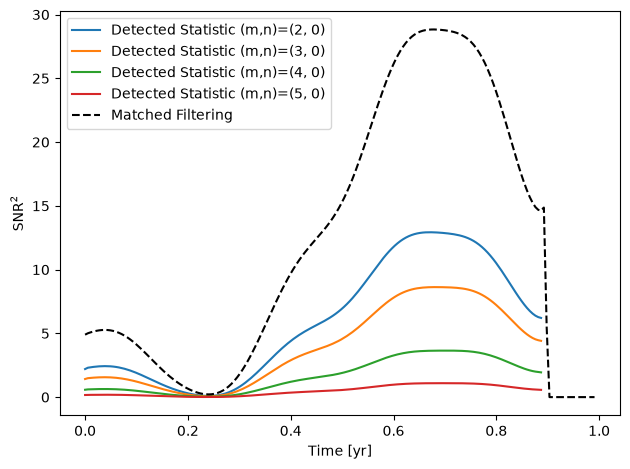

In [11]:
sum_check = 0.0
plt.figure()
for key in S_sig_dict.keys():
    S_signal = S_sig_dict[key]
    S_data = S_data_dict[key]
    plt.plot(t_alpha/YRSID_SI, S_signal, label=f'Detected Statistic (m,n)={key}')
    sum_check += np.nan_to_num(S_signal).sum()/(mfilter_hh.sum() * window_factor)
    print(f"Sum check : {sum_check}")
plt.plot(t_alpha/YRSID_SI, mfilter_hh, label='Matched Filtering', color='k', linestyle='--')
plt.xlabel('Time [yr]')
plt.ylabel('SNR$^2$')
plt.legend()
plt.tight_layout()
print(f"Total sum check: {sum_check}")

# Search

In [12]:
sum_data = 0.0
for key in [(2,0)]:#, (3,0), (4,0), (5,0)]:
    S_data = S_data_dict[key]
    sum_data += np.nan_to_num(S_data).sum()
print(f"Total sum data: {sum_data}")

Total sum data: 1288.306299892937


In [13]:
print(get_loglike(true_values[:-1], t_alpha, noise_sfts), window_factor * (f_alpha != 0.0).sum())

154.10789893935151 144.37082248259154


### Optimisation (differential evolution)

`func` minimises $-\mathcal D$ on the noise-free `signal_sfts`, so the printed values ($\approx488.5$) are the signal term only, with no noise baseline. For comparison the data SFTs give $\mathcal D(d)\approx646.6$ in the earlier cell, i.e. $\mathcal D(h)+\mathcal D(n)$ ($488.5+155.2$) plus a cross term of about $+2.9$ (§4). On noise-free data the true parameters need not give the global maximum of $\mathcal D$, because the template is approximate (rectangular kernel, $\rho\approx T/S_n$, only $f$ and $\dot f$ in the chirp); the small improvement over the truth ($488.63$ versus $488.54$) is of that order. When running on data with noise, compare candidates with $\mathcal D-N_{\rm active}f_w$ (§5), and use $\ln\mathcal L=\mathcal D$, not $2\mathcal D$, if the same statistic is later used for sampling.

In [14]:
from scipy.optimize import differential_evolution

delta = 0.1  # 10% variation around true values
diff_ev_bounds = np.asarray([(el * (1-delta), el * (1+delta)) for el in true_values[:-1]])

def func(params):
    try:
        minus_ll = -get_loglike(params, t_alpha, injection_dict['signal_sfts'])
    except Exception as e:
        minus_ll = 1e50
    return minus_ll

init = np.random.uniform(low=diff_ev_bounds[:, 0], high=diff_ev_bounds[:, 1], size=(32, diff_ev_bounds.shape[0]))
init[0] = true_values[:-1]
init.shape, diff_ev_bounds.shape

((32, 5), (5, 2))

In [15]:
# from multiprocess import Pool

# with Pool(processes=8) as pool:
#     out = differential_evolution(func, diff_ev_bounds, strategy='best1bin', atol=0.0, init=init, workers=pool.map,
#                                 maxiter=100, tol=0.0, mutation=(0.5, 1), recombination=0.7, seed=42, disp=True)

out = differential_evolution(func, diff_ev_bounds, strategy='best1bin', atol=0.0, init=init,
    maxiter=30, tol=0.0, mutation=(0.5, 1), recombination=0.7, seed=42, disp=True, polish=False)


differential_evolution step 1: f(x)= -485.1134218438534
differential_evolution step 2: f(x)= -485.1134218438534
differential_evolution step 3: f(x)= -485.1134218438534
differential_evolution step 4: f(x)= -485.1134218438534
differential_evolution step 5: f(x)= -485.1134218438534
differential_evolution step 6: f(x)= -485.1134218438534
differential_evolution step 7: f(x)= -485.1134218438534
differential_evolution step 8: f(x)= -485.1134218438534
differential_evolution step 9: f(x)= -485.1134218438534
differential_evolution step 10: f(x)= -485.1134218438534
differential_evolution step 11: f(x)= -485.1134218438534
differential_evolution step 12: f(x)= -485.1134218438534
differential_evolution step 13: f(x)= -485.1134218438534
differential_evolution step 14: f(x)= -485.1134218438534
differential_evolution step 15: f(x)= -485.1134218438534
differential_evolution step 16: f(x)= -485.1134218438534
differential_evolution step 17: f(x)= -485.1134218438534
differential_evolution step 18: f(x)= -4

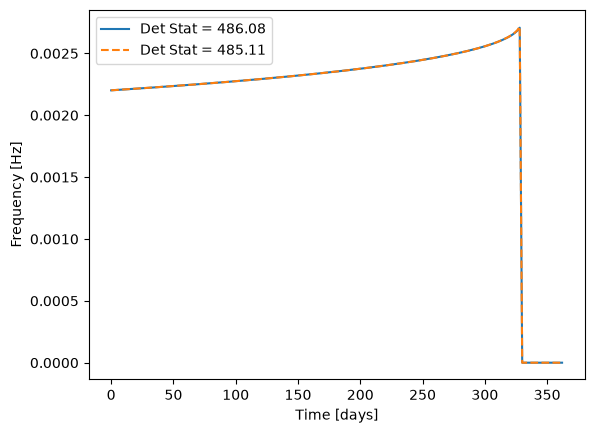

In [16]:
f_, fdot_, _ = f_fdot_fddot(out.x, t_alpha)
f_best = jnp.abs(jnp.asarray(m*f_[0] + n*f_[1], dtype=jnp.float64))
f_true = jnp.abs(jnp.asarray(m*f_phi_r[0] + n*f_phi_r[1], dtype=jnp.float64))
plt.figure()
plt.plot(t_alpha/86400.0, f_best, label="Det Stat = {:.2f}".format(get_loglike(out.x, t_alpha, injection_dict['signal_sfts'])))
plt.plot(t_alpha/86400.0, f_true, '--', label="Det Stat = {:.2f}".format(get_loglike(true_values[:-1], t_alpha, injection_dict['signal_sfts'])))
plt.xlabel('Time [days]')
plt.ylabel('Frequency [Hz]')
plt.legend()
plt.show()